# Lab 3: Document Classification (Part 2)

### Overview
This topic builds on the activities of the previous topic on sentiment analysis. You will be focussing on the movie review corpus with a view to investigating the following issues.

- Evaluation metrics for classifier performance
- What is the impact of varying training data size? To what extent does increasing the quantity of training data improve classifier performance?

By this stage, you should be very comfortable with Python's [list comprehensions](http://docs.python.org/tutorial/datastructures.html#list-comprehensions) and [slice](http://bergbom.blogspot.co.uk/2011/04/python-slice-notation.html) notation.



>To access functionality defined in previous notebooks, copy the functions defined in Week3Labs into a `utils.py` file and then import it into the notebook.  There is a `utils.py` file included with these resources which you can update.

### Creating `utils.py` in Colab

Run the cell below to write the utility helper functions into `utils.py`. You can edit this cell to add, update, or paste your functions from previous weeks, then re-run it to save the changes.

In [ ]:
%%writefile utils.py
# Paste your helper functions from previous labs here
from nltk import FreqDist

class SimpleClassifier:
    def __init__(self, pos_words, neg_words):
        self.pos_words = set(pos_words)
        self.neg_words = set(neg_words)

    def classify(self, doc):
        # doc is a FreqDist of words. We count occurrences of positive and negative words.
        pos_score = sum(doc[w] for w in self.pos_words if w in doc)
        neg_score = sum(doc[w] for w in self.neg_words if w in doc)
        if pos_score >= neg_score:
            return "pos"
        else:
            return "neg"

    def classify_many(self, docs):
        return [self.classify(doc) for doc in docs]

def normalise(wordlist):
    return [word.lower() for word in wordlist if word.isalpha()]

def split_data(data, ratio=0.7):
    split_point = int(len(data) * ratio)
    return data[:split_point], data[split_point:]

# --- New Auto-Wordlist Classifiers for Exercise 3 ---

class SimpleClassifier_mf(SimpleClassifier):
    def __init__(self, k):
        self.k = k
        super().__init__([], [])

    def train(self, training_data):
        pos_freq = FreqDist()
        neg_freq = FreqDist()
        for doc, label in training_data:
            if label == 'pos':
                pos_freq.update(doc)
            else:
                neg_freq.update(doc)

        # Take the top k most frequent words in positive and negative sets
        pos_words = [word for word, count in pos_freq.most_common(self.k)]
        neg_words = [word for word, count in neg_freq.most_common(self.k)]

        # Remove the intersection (words that are highly frequent in BOTH)
        self.pos_words = set(pos_words) - set(neg_words)
        self.neg_words = set(neg_words) - set(pos_words)

class SimpleClassifier_ot(SimpleClassifier):
    def __init__(self, threshold):
        self.threshold = threshold
        super().__init__([], [])

    def train(self, training_data):
        pos_freq = FreqDist()
        neg_freq = FreqDist()
        for doc, label in training_data:
            if label == 'pos':
                pos_freq.update(doc)
            else:
                neg_freq.update(doc)

        # Only keep words that appear strictly above the threshold frequency
        pos_words = [word for word, count in pos_freq.items() if count > self.threshold]
        neg_words = [word for word, count in neg_freq.items() if count > self.threshold]

        self.pos_words = set(pos_words) - set(neg_words)
        self.neg_words = set(neg_words) - set(pos_words)

Overwriting utils.py


In [ ]:
##uncomment the following lines on colab

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#other needed imports
from nltk.corpus import movie_reviews
import random
import pandas as pd
#this next line will ensure pandas graphs are plotted in the notebook
%matplotlib inline

##download stopwords and movie_reviews - need to do this every session on colab
import nltk
nltk.download('stopwords')
nltk.download('movie_reviews')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!


True

In [ ]:
#set your system path to the current working directory in Colab
import sys
sys.path.append('/content')

#import code to setup training and testing data, wordlist classifiers and NB classifiers
from utils import *


## Evaluation Metrics for Classifier Performance

### Accuracy
Here is code for an evaluation function <code>evaluate_wordlist_classifier</code> which can be used to determine how well a word_list classifier performs. This function returns the <b>accuracy</b> of a classifier. The accuracy metric is defined as the proportion of documents that were correctly classified.  Look at the code and make sure you understand what it is doing

In [ ]:
def classifier_evaluate(cls, test_data):
    '''
    cls: an instance of a classifier object which has a classify method which returns "pos" or "neg"
    test_data: a list of pairs where each pair is a FreqDist rep of a doc and its label

    returns: float point number which is the accuracy of the classifier on the test data provided
    '''
    acc = 0
    docs,goldstandard=zip(*test_data) #note this neat pythonic way of turning a list of pairs into a pair of lists
    #pass all of the docs to the classifier and get back a list of predictions
    predictions=cls.classify_many(docs)
    #zip the predictions with the goldstandard labels and compare
    for prediction,goldlabel in zip(predictions,goldstandard):
        if prediction==goldlabel:
            acc+=1

    return acc / (len(test_data))

Now we need some data to train and test our classifier on.  We are going to make use of the code from the lab_3_1.  

In [ ]:
def get_train_test_data():
    # STEP 1: Retrieve the lists of file names (IDs) for positive and negative reviews from NLTK
    pos_review_ids = movie_reviews.fileids('pos')
    neg_review_ids = movie_reviews.fileids('neg')

    # STEP 2: Split both positive and negative review files into training (70%) and testing (30%) sets
    # (Using the split_data helper function we imported from utils.py)
    pos_train_ids, pos_test_ids = split_data(pos_review_ids)
    neg_train_ids, neg_test_ids = split_data(neg_review_ids)

    # STEP 3: Load the actual words for each review file and label them ('pos' or 'neg')
    # This creates lists of pairs like: ([list, of, words], 'pos')
    training = [(movie_reviews.words(f), 'pos') for f in pos_train_ids] + [(movie_reviews.words(f), 'neg') for f in neg_train_ids]
    testing = [(movie_reviews.words(f), 'pos') for f in pos_test_ids] + [(movie_reviews.words(f), 'neg') for f in neg_test_ids]

    # STEP 4: Clean the text (normalization) and convert them to word frequency counts (Bag-of-Words)
    # For each review, we lowercase/remove punctuation, and then build a Frequency Distribution (FreqDist)
    training_norm = [(FreqDist(normalise(wordlist)), label) for (wordlist, label) in training]
    testing_norm = [(FreqDist(normalise(wordlist)), label) for (wordlist, label) in testing]

    # STEP 5: Return the fully prepared training and testing sets
    return training_norm, testing_norm

In [ ]:
from nltk import FreqDist

random.seed(41)  #set the random seeds so these random splits are always the same
training,testing=get_train_test_data()

training[0]

(FreqDist({'the': 46, 'and': 21, 'in': 18, 'a': 15, 'to': 15, 'of': 14, 's': 11, 'it': 11, 't': 10, 'from': 8, ...}),
 'pos')

We are now going to use this function to start evaluating our classifiers from last week.  Lets first try the SimpleClassifier

In [ ]:
# The original SimpleClassifier assigns everything to the positive class by default.
# If we instantiate it with empty lists, both pos_score and neg_score will be 0.
# Since pos_score >= neg_score (0 >= 0) is True, it will classify everything as "pos".

baseline_classifier = SimpleClassifier(pos_words=[], neg_words=[])

# Evaluate the classifier on our testing data
baseline_accuracy = classifier_evaluate(baseline_classifier, testing)
print(f"Baseline Classifier Accuracy: {baseline_accuracy}")

Baseline Classifier Accuracy: 0.5


If you have run the cell above without updating the SimpleClassifier code you should see that the accuracy is 0.5 i.e., 50%. The original SimpleClassifier just assigns everything to the positive class.  Since it is a binary classification decision and the classes are balanced, it will get 50% of the decisions correct (those that are positive) and 50% of the decisions incorrect (those that are actually negative).  This is the **baseline** result for this kind of classification task.  We obviously want to build classifiers that do better than this.

### Exercise 1

Now you try one of the classifiers that you wrote that selects positive and negative words from the training data.  Hopefully, this will perform better than the baseline of 50%.

In [ ]:
#Create a new classifier
#Make sure you have updated the code in utils.py to contain your WordList Classifier
#If you update the utils.py code mid-session, you will need to restart the runtime / kernel in order to force it to import the new updated code
movie_classifier2 = SimpleClassifier_mf(100)
#train it
movie_classifier2.train(training)
#evaluate it on the test data
score=classifier_evaluate(movie_classifier2,testing)
print(score)

0.665


## Precision, Recall and F1 score etc

When classes are unbalanced, evaluating classifiers in terms of accuracy can be misleading.  For example, if 10% of documents are relevant and 90% of documents are irrelevant, then a classifier which labels all documents as irrelevant will obtain an accuracy of 90%.  This sounds good but is actually useless. More useful metrics for evaluation of performance are precision, recall and F1 score.  These metrics allow us to distinguish the different types of errors our classifiers make.

For each class, $c$, we need to keep a record of
* True Positives: $TP=|\{i|\mbox{prediction}(i)=\mbox{label}(i)=c\}|$
* False Negatives: $FN=|\{i|\mbox{prediction}(i)\neq \mbox{label}(i)=c\}|$
* False Positives: $FP=|\{i|\mbox{label}(i) \neq \mbox{prediction}(i)=c\}|$
* True Negatives: $TN=|\{i|\mbox{prediction}(i)=\mbox{label}(i)\neq c\}|$

Note the symmetry in the binary classification task (the TN for one class are the TP for the other class and so on).  Therefore, in binary classification, we just record these values and compute the following evaluation metrics for a single class (e.g. "Relevant" or "Positive")

* Precision:
\begin{eqnarray*}
P=\frac{TP}{TP+FP}
\end{eqnarray*}
* Recall:
\begin{eqnarray*}
R=\frac{TP}{TP+FN}
\end{eqnarray*}
* F1-score:
\begin{eqnarray*}
F1 = \frac{2\times P\times R}{P+R}
\end{eqnarray*}


 ### Exercise 2.1

 The code below defines a ConfusionMatrix class for the binary classification task.  Currently, it will compute the number of TPs, FPs, FNs and TNs.  Test it out with predictions and test data for our sentiment analysis task.

In [ ]:
class ConfusionMatrix:
    def __init__(self, predictions, goldstandard, classes=("pos", "neg")):
        (self.c1, self.c2) = classes
        self.TP = 0
        self.FP = 0
        self.FN = 0
        self.TN = 0
        for p, g in zip(predictions, goldstandard):
            if g == self.c1:
                if p == self.c1:
                    self.TP += 1
                else:
                    self.FN += 1
            elif p == self.c1:
                self.FP += 1
            else:
                self.TN += 1

    def precision(self):
        if (self.TP + self.FP) == 0:
            return 0.0
        return self.TP / (self.TP + self.FP)

    def recall(self):
        if (self.TP + self.FN) == 0:
            return 0.0
        return self.TP / (self.TP + self.FN)

    def f1(self):
        p = self.precision()
        r = self.recall()
        if (p + r) == 0:
            return 0.0
        return (2 * p * r) / (p + r)

In [ ]:
mystring="fred"
mystring.isalpha()

True

In [ ]:
#docs will contain the documents to classify, labels contains the corresponding gold standard labels
docs,labels=zip(*testing)
senti_cm=ConfusionMatrix(movie_classifier1.classify_many(docs),labels)
print(senti_cm.TP)
print(senti_cm.FP)
print(senti_cm.TN)
print(senti_cm.FN)

284
209
91
16


In [ ]:
list[Any](labels)

['pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',
 'pos',


In [ ]:
senti_cm.precision()

0.5760649087221096

### Exercise 2.2
* Add functionality to the ConfusionMatrix class code to compute precision, recall and F1 score
* Use your code to evaluate the performance of the different classifiers you have constructed.
* Interpret your results

### Exercise 2.2 Implementation & Tutoring Explanation
We will dynamically add `precision`, `recall`, and `f1` methods to our existing `ConfusionMatrix` class (or re-define the class to incorporate them) and use them to evaluate our classifiers.

## Investigating the impact of the quantity of training data
We will begin by exploring the impact on classification accuracy of using different quantities of training data.




Run the code in the cell below several times.  Each time it should generate a new sample of review data, train the classifiers and evaluate them.

Averaged accuracy over 10 runs:
- Word List MF:     0.634
- Word List Thresh: 0.607


(0.0, 1.0)

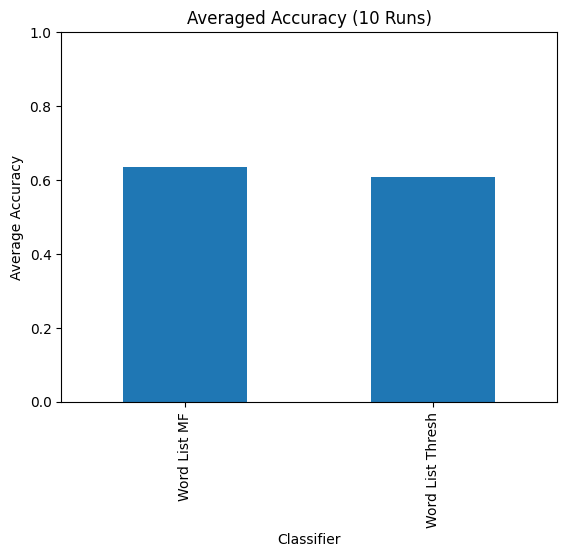

In [ ]:
# Reset the random seed to a completely random state so it's different every run
import random
random.seed(None)

# Dynamically shuffle the dataset keys and get a fresh, random split
def get_random_train_test_data():
    pos_review_ids = list(movie_reviews.fileids('pos'))
    neg_review_ids = list(movie_reviews.fileids('neg'))

    # Shuffle the file IDs randomly on each execution
    random.shuffle(pos_review_ids)
    random.shuffle(neg_review_ids)

    pos_train_ids, pos_test_ids = split_data(pos_review_ids)
    neg_train_ids, neg_test_ids = split_data(neg_review_ids)

    training = [(movie_reviews.words(f), 'pos') for f in pos_train_ids] + [(movie_reviews.words(f), 'neg') for f in neg_train_ids]
    testing = [(movie_reviews.words(f), 'pos') for f in pos_test_ids] + [(movie_reviews.words(f), 'neg') for f in neg_test_ids]

    training_norm = [(FreqDist(normalise(wordlist)), label) for (wordlist, label) in training]
    testing_norm = [(FreqDist(normalise(wordlist)), label) for (wordlist, label) in testing]
    return training_norm, testing_norm

# Run the experiment 10 times to average out the variation
num_runs = 10
word_list_size = 100
threshold = 100

mf_accuracies = []
thresh_accuracies = []

for run in range(num_runs):
    # Generate a unique training and testing dataset on each iteration
    training, testing = get_random_train_test_data()

    # Train and evaluate Word List MF classifier
    classifier_mf = SimpleClassifier_mf(word_list_size)
    classifier_mf.train(training)
    mf_accuracies.append(classifier_evaluate(classifier_mf, testing))

    # Train and evaluate Word List Thresh classifier
    classifier_ot = SimpleClassifier_ot(threshold)
    classifier_ot.train(training)
    thresh_accuracies.append(classifier_evaluate(classifier_ot, testing))

# Compute average accuracies across all runs
avg_mf_accuracy = sum(mf_accuracies) / num_runs
avg_thresh_accuracy = sum(thresh_accuracies) / num_runs

print(f"Averaged accuracy over {num_runs} runs:")
print(f"- Word List MF:     {avg_mf_accuracy:.3f}")
print(f"- Word List Thresh: {avg_thresh_accuracy:.3f}")

# Visualize the stable, averaged results
df_avg = pd.DataFrame([
    ["Word List MF", avg_mf_accuracy],
    ["Word List Thresh", avg_thresh_accuracy]
])
ax = df_avg.plot.bar(title=f"Averaged Accuracy ({num_runs} Runs)", legend=False, x=0)
ax.set_ylabel("Average Accuracy")
ax.set_xlabel("Classifier")
ax.set_ylim(0, 1.0)

The accuracy of Word List MF classifier is 0.6366666666666667
The accuracy of Word List Thresh classifier is 0.5766666666666667


,0,1
0,Word List MF,0.636667
1,Word List Thresh,0.576667


(0.0, 1.0)

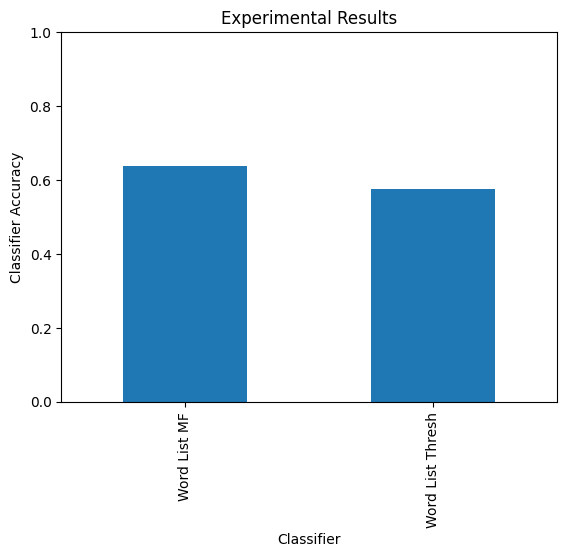

In [ ]:
training,testing=get_random_train_test_data()

word_list_size = 100
threshold=100
classifiers={"Word List MF":SimpleClassifier_mf(word_list_size),
             "Word List Thresh":SimpleClassifier_ot(threshold)}

results=[]
for name,classifier in classifiers.items():
    classifier.train(training)
    accuracy=classifier_evaluate(classifier,testing)
    print("The accuracy of {} classifier is {}".format(name,accuracy))
    results.append((name,accuracy))

df = pd.DataFrame(results)
display(df)
ax = df.plot.bar(title="Experimental Results",legend=False,x=0)
ax.set_ylabel("Classifier Accuracy")
ax.set_xlabel("Classifier")
ax.set_ylim(0,1.0)

As you can see, the classifiers have different accuracies on different runs.

### Exercise 3.1
Copy the cell above and move the copy to be positioned below this cell. Then adapt the code so that the accuracy reported for each classifier is the average across multiple runs.

### Exercise 3.2
Adapt the code so that it calculates average precision, recall and F1-score rather than average accuracy.

=== Averaged Metrics over 10 Runs ===


,Classifier,Precision,Recall,F1-Score
0,Word List MF,0.637624,0.687333,0.661313
1,Word List Thresh,0.566885,0.937000,0.705514


Text(0.5, 0, 'Classifier')

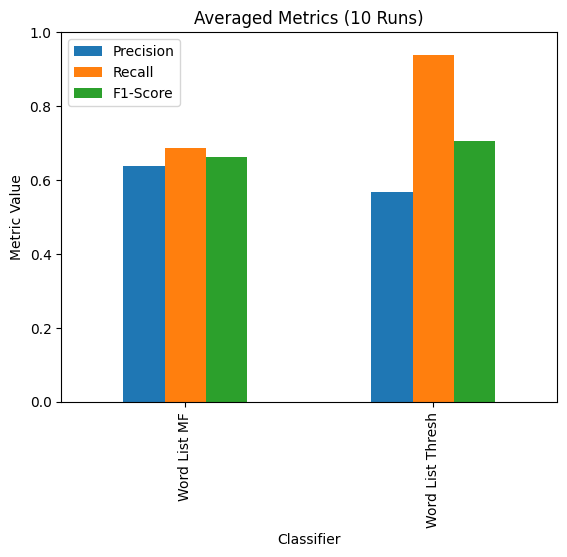

In [ ]:
import pandas as pd
import random
random.seed(None)

word_list_size = 100
threshold = 100

# Prepare classifiers
classifiers = {
    "Word List MF": SimpleClassifier_mf(word_list_size),
    "Word List Thresh": SimpleClassifier_ot(threshold)
}

number_of_runs = 10
records = []

for run in range(number_of_runs):
    # 1. Get a fresh, randomized split of training and testing data
    training, testing = get_random_train_test_data()
    gold_labels = [label for doc, label in testing]
    test_docs = [doc for doc, label in testing]

    for name, classifier in classifiers.items():
        # 2. Train and get predictions
        classifier.train(training)
        predictions = classifier.classify_many(test_docs)

        # 3. Compute metrics using our ConfusionMatrix class
        cm = ConfusionMatrix(predictions, gold_labels)

        # Record metrics for this individual run
        records.append({
            "Classifier": name,
            "Precision": cm.precision(),
            "Recall": cm.recall(),
            "F1-Score": cm.f1()
        })

# 4. Use Pandas' groupby to easily calculate the average of all runs
df_runs = pd.DataFrame(records)
df_avg = df_runs.groupby("Classifier").mean().reset_index()

print(f"=== Averaged Metrics over {number_of_runs} Runs ===")
display(df_avg)

# 5. Visualize the multi-metric comparative results
ax = df_avg.plot.bar(x="Classifier", title=f"Averaged Metrics ({number_of_runs} Runs)", ylim=(0, 1.0))
ax.set_ylabel("Metric Value")
ax.set_xlabel("Classifier")

### Exercise 3.3
Investigate the impact of training data size on the performance of both word list classifiers, using a range of subsets of movie reviews.

Hints and tips.
- You can copy the code cell that you created for the last exercise, and place the copy below this cell. Then adapt the code to determine accuracy, precision, recall and F1-score for each classifier on each subset.

- Use the `sample` function from the random module.
- Remember, the full data set has 1000 positive and 1000 negative reviews.
- You should continue to use 30% of the data for testing, so this means that we have up to 700 positive and 700 negative reviews to sample from.
- Make sure that you are selecting samples that have an equal number of positive and negative reviews.
- Consider (at least) the following sample sizes: 2, 10, 50, 100, 200, 400, 600 and 700.
- Note that the sample size is not the total number of reviews, but the number of positive reviews (which is also equal to the number of negative reviews).


**Interpret your results**

In [ ]:
from random import sample

sample_sizes=[2,10,50,100,200,400,600, 700]
results={}



Running experiments for training sample size: 2...
Running experiments for training sample size: 10...
Running experiments for training sample size: 50...
Running experiments for training sample size: 100...
Running experiments for training sample size: 200...
Running experiments for training sample size: 400...
Running experiments for training sample size: 600...
Running experiments for training sample size: 700...

=== Averaged Experimental Results ===


,SampleSize,Classifier,Accuracy,Precision,Recall,F1-Score
0,2,Word List MF,0.530667,0.542746,0.667333,0.558720
1,2,Word List Thresh,0.500000,0.500000,1.000000,0.666667
2,10,Word List MF,0.552167,0.562275,0.526000,0.528407
3,10,Word List Thresh,0.500667,0.455837,0.729000,0.513066
4,50,Word List MF,0.638167,0.627528,0.686000,0.654053
5,50,Word List Thresh,0.526333,0.545491,0.608333,0.530015
6,100,Word List MF,0.644833,0.629927,0.705333,0.664726
7,100,Word List Thresh,0.541167,0.524086,0.946333,0.673529
8,200,Word List MF,0.639500,0.625927,0.694000,0.658061
9,200,Word List Thresh,0.580833,0.554684,0.920333,0.686767


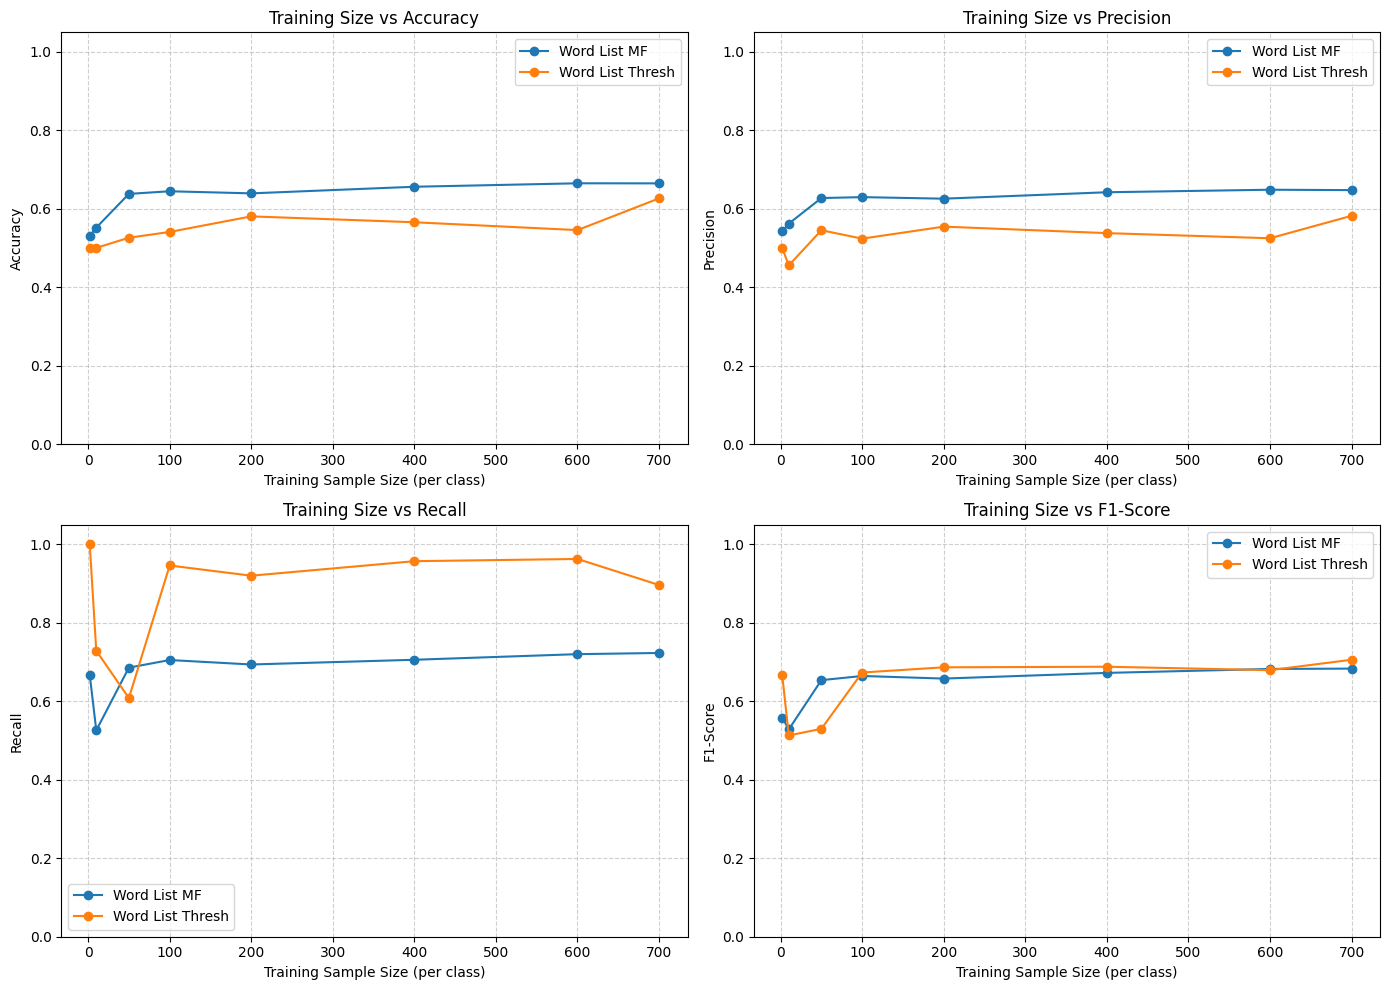

In [ ]:
import random
import pandas as pd
import matplotlib.pyplot as plt
from nltk import FreqDist
from utils import *

# Reset seed for random, non-deterministic sampling across runs
random.seed(None)

# Define the sample sizes (number of positive reviews = number of negative reviews)
sample_sizes = [2, 10, 50, 100, 200, 400, 600, 700]
number_of_runs = 10
word_list_size = 100
threshold = 100

# Prepare the full pool of file IDs
pos_review_ids = list(movie_reviews.fileids('pos'))
neg_review_ids = list(movie_reviews.fileids('neg'))

# Split into fixed test pools (30%) and training pools (70%)
# We must keep testing static so that performance is comparable across all training sizes
pos_train_pool, pos_test_pool = split_data(pos_review_ids, ratio=0.7)
neg_train_pool, neg_test_pool = split_data(neg_review_ids, ratio=0.7)

# Prepare static testing data
testing_raw = [(movie_reviews.words(f), 'pos') for f in pos_test_pool] + [(movie_reviews.words(f), 'neg') for f in neg_test_pool]
testing = [(FreqDist(normalise(wordlist)), label) for (wordlist, label) in testing_raw]
test_docs, gold_labels = zip(*testing)

records = []

# Loop over each target training sample size
for size in sample_sizes:
    print(f"Running experiments for training sample size: {size}...")

    for run in range(number_of_runs):
        # Randomly sample 'size' amount of reviews from our training pools
        sampled_pos_ids = random.sample(pos_train_pool, size)
        sampled_neg_ids = random.sample(neg_train_pool, size)

        # Prepare the training data subset for this run
        training_raw = [(movie_reviews.words(f), 'pos') for f in sampled_pos_ids] + [(movie_reviews.words(f), 'neg') for f in sampled_neg_ids]
        training = [(FreqDist(normalise(wordlist)), label) for (wordlist, label) in training_raw]

        # Instantiate and train classifiers
        classifier_mf = SimpleClassifier_mf(word_list_size)
        classifier_mf.train(training)

        classifier_ot = SimpleClassifier_ot(threshold)
        classifier_ot.train(training)

        # Evaluate Word List MF
        preds_mf = classifier_mf.classify_many(test_docs)
        cm_mf = ConfusionMatrix(preds_mf, gold_labels)
        acc_mf = classifier_evaluate(classifier_mf, testing)

        records.append({
            "SampleSize": size,
            "Classifier": "Word List MF",
            "Accuracy": acc_mf,
            "Precision": cm_mf.precision(),
            "Recall": cm_mf.recall(),
            "F1-Score": cm_mf.f1()
        })

        # Evaluate Word List Thresh
        preds_ot = classifier_ot.classify_many(test_docs)
        cm_ot = ConfusionMatrix(preds_ot, gold_labels)
        acc_ot = classifier_evaluate(classifier_ot, testing)

        records.append({
            "SampleSize": size,
            "Classifier": "Word List Thresh",
            "Accuracy": acc_ot,
            "Precision": cm_ot.precision(),
            "Recall": cm_ot.recall(),
            "F1-Score": cm_ot.f1()
        })

# Combine and average the results over the runs
df_runs = pd.DataFrame(records)
df_avg = df_runs.groupby(["SampleSize", "Classifier"]).mean().reset_index()

print("\n=== Averaged Experimental Results ===")
display(df_avg)

# Plot the curves for each metric
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, metric in enumerate(metrics):
    ax = axes[idx]
    for classifier_name in ["Word List MF", "Word List Thresh"]:
        subset = df_avg[df_avg["Classifier"] == classifier_name]
        ax.plot(subset["SampleSize"], subset[metric], marker='o', label=classifier_name)
    ax.set_title(f"Training Size vs {metric}")
    ax.set_xlabel("Training Sample Size (per class)")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1.05)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()

plt.tight_layout()
plt.show()

### Definition of the Two Classifier Models

Both models are built upon the rule-based **`SimpleClassifier`**, which counts the number of positive and negative sentiment keywords present in a document and makes a classification decision based on which count is higher.

1. **`Word List MF` (Most Frequent):**
   - **Strategy:** It aggregates the word frequencies across all training documents in each class and selects the top $K$ (e.g., $100$) most frequent words for the positive and negative word lists.
   - **Overlap Removal:** Words that appear in the top list of *both* classes are removed to keep the classification signals distinct.
   - **Characteristics:** Highly balanced model focusing on common indicator words.

2. **`Word List Thresh` (Over Threshold):**
   - **Strategy:** Instead of selecting a fixed number of words, it selects *every* word that has an absolute frequency count strictly greater than a threshold value (e.g., $>100$) in the training corpus.
   - **Overlap Removal:** Words that exceed the threshold in both classes are discarded.
   - **Characteristics:** Produces asymmetric and expansive word lists, typically yielding extremely high recall but lower precision.

=== Overall Average Accuracy by Training Sample Size ===


Classifier,Word List MF,Word List Thresh
SampleSize,,
2,0.530667,0.500000
10,0.552167,0.500667
50,0.638167,0.526333
100,0.644833,0.541167
200,0.639500,0.580833
400,0.656333,0.565833
600,0.665167,0.545833
700,0.665000,0.626667


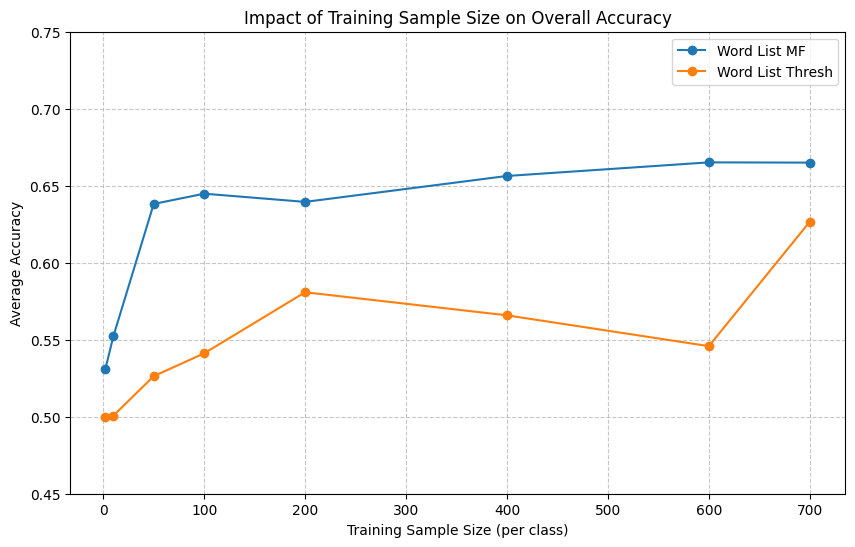

In [ ]:
# Calculate and plot overall average accuracy for the two models
df_accuracy_avg = df_runs.groupby(["SampleSize", "Classifier"])["Accuracy"].mean().reset_index()

print("=== Overall Average Accuracy by Training Sample Size ===")
display(df_accuracy_avg.pivot(index="SampleSize", columns="Classifier", values="Accuracy"))

# Plotting the Accuracy Curves
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
for name in ["Word List MF", "Word List Thresh"]:
    subset = df_accuracy_avg[df_accuracy_avg["Classifier"] == name]
    plt.plot(subset["SampleSize"], subset["Accuracy"], marker='o', label=name)

plt.title("Impact of Training Sample Size on Overall Accuracy")
plt.xlabel("Training Sample Size (per class)")
plt.ylabel("Average Accuracy")
plt.ylim(0.45, 0.75)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

My answer:

